InstanceNumber metadata present in all files: True

MRI shape:
(256, 256, 256)

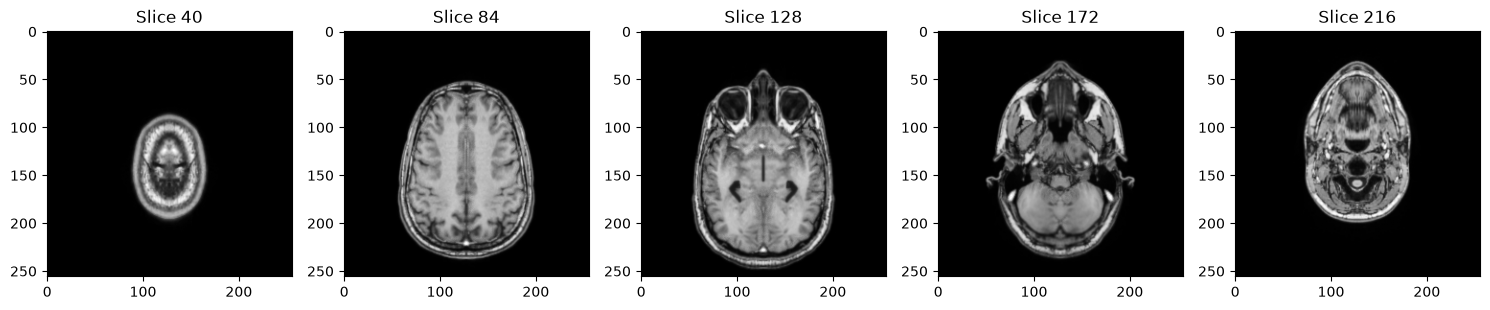

In [ ]:
import pydicom # Handling dicom
import numpy as np # Tensors
import matplotlib.pyplot as plt # Plotting
import os # File system
from rich import print # Logging (I like coloered output)

# Input data as provided
DATA_DIR = "data/Aneurysm_MRI"
# Retrieving all filenames
dicom_files = [f for f in os.listdir(DATA_DIR) if f.lower().endswith('.dcm')]
dicom_files.sort()

# Loading each slice with dcmread in list
slices = [pydicom.dcmread(os.path.join(DATA_DIR, f)) for f in dicom_files]
# Do all .dcm file have an instance number?
slices_have_idx = all([s.InstanceNumber is not None for s in slices])
print(f"InstanceNumber metadata present in all files: {slices_have_idx}")

# Reordering based on slice idx
if slices_have_idx:
    slices.sort(key=lambda s: int(s.InstanceNumber)) # metadata is string

# List to tensor (accessign pixel_array key)
vol3d = np.stack([s.pixel_array for s in slices]) 
D,H,W = vol3d.shape # Depth - height - width
print("MRI shape:", vol3d.shape) 

# Plotting 5 slices evenly spaced from 40 to D-40 (first and last are all zeros)
FIRST_SLICE, LAST_SLICE = 40, D-40
plt.figure(figsize=(15,3))
for pltidx, sliceidx in enumerate(np.linspace(FIRST_SLICE, LAST_SLICE, 5).astype(int)):
    plt.subplot(1,5,pltidx+1)
    plt.imshow(vol3d[sliceidx-1], cmap='gray')
    plt.title(f"Slice {sliceidx}")
plt.tight_layout()
plt.show()

